In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [13]:
df = pd.read_csv("sales_data_sample.csv", encoding = ("unicode_escape"))
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [14]:
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [16]:
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

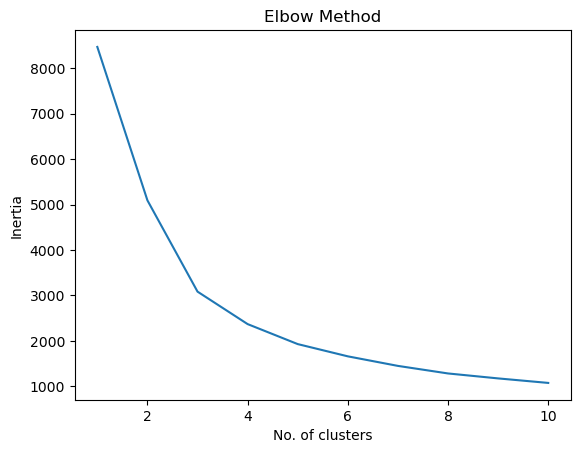

In [18]:
plt.plot(range(1,11), inertia)
plt.xlabel("No. of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [20]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"]= kmeans.fit_predict(X_scaled)
print(df[["QUANTITYORDERED", "PRICEEACH", "SALES", "Cluster"]].head())

   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        1
4               49     100.00  5205.27        1


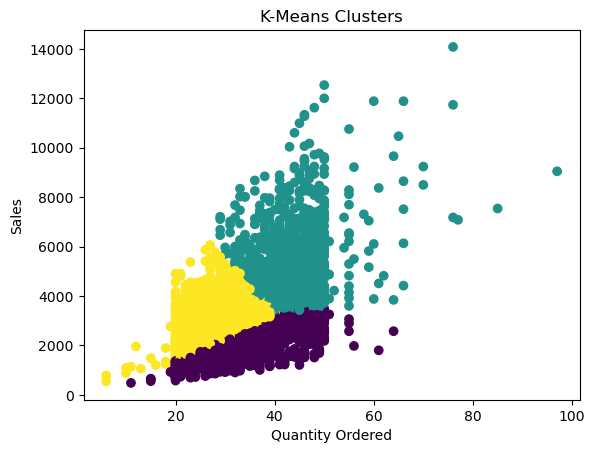

In [21]:
plt.scatter(df["QUANTITYORDERED"], df["SALES"], c=df["Cluster"])
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clusters")
plt.show()